[[0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]
[[0.51727708 0.35437459 0.12834833]
 [0.51727708 0.35437459 0.12834833]
 [0.51727708 0.35437459 0.12834833]
 [0.51727708 0.35437459 0.12834833]
 [0.51727708 0.35437459 0.12834833]
 [0.51727708 0.35437459 0.12834833]
 [0.51727708 0.35437459 0.12834833]
 [0.51727708 0.35437459 0.12834833]
 [0.51727708 0.35437459 0.12834833]
 [0.51727708 0.35437459 0.12834833]]
Вероятности: [np.float64(0.5172770815494155), np.float64(0.354374590797289), np.float64(0.1283483276532955)]
F1-score: 0.3738


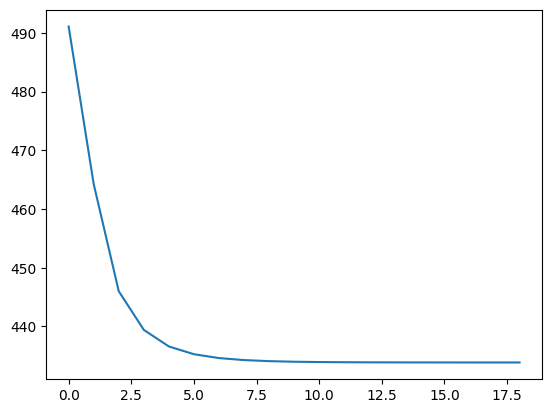

In [ ]:
import numpy as np
import pandas as pd
import numdifftools as nd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, classification_report, f1_score

def relu(x):
  return max([0, x])

def leakyrelu(x):
  return max([0.1 * x, x])

def elu(x, alpha = 0.1):
  if x >= 0:
    return x
  else:
    return alpha * (np.exp(x) - 1)

class Network:
  def __init__(self):
    self.X = None
    self.y = None
    self.weights = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

  def forward(self, x, w):
    out1 = elu(x[0] * w[0] + x[1] * w[1] + x[2] * w[2] + w[3])
    out2 = relu(out1 * w[4] + w[6])
    out3 = relu(out1 * w[5] + w[7])
    out4 = leakyrelu(out2 * w[8] + out3 * w[9] + w[10])
    out5 = relu(out4 * w[11] + w[14])
    out6 = relu(out4 * w[12] + w[15])
    out7 = relu(out4 * w[13] + w[16])

    out5_sm = np.exp(out5) / (np.exp(out5) + np.exp(out6) + np.exp(out7))
    out6_sm = np.exp(out6) / (np.exp(out5) + np.exp(out6) + np.exp(out7))
    out7_sm = np.exp(out7) / (np.exp(out5) + np.exp(out6) + np.exp(out7))
    return [out5_sm, out6_sm, out7_sm]

  def predict(self, X, weights=None):
    if weights is None:
      weights = self.weights
    y_hat = []
    for x_i in X:
      pred = self.forward(x_i, weights)
      y_hat.append(pred)
    return np.array(y_hat)

  def loss(self, weights):
    y_hat = self.predict(self.X, weights)
    p = []
    for i, true_col in zip(range(len(self.y)), self.y.argmax(axis=1)):
      p.append(y_hat[i, true_col])
    logloss = -np.log(p).sum()
    return logloss

  def fit(self, X, y, learning_rate=0.01, eps=1e-4, max_iter=1000):
    self.X = X
    self.y = y

    grad_loss = nd.Gradient(self.loss, step=1e-4)
    weights = self.weights.copy()
    loss_history = [self.loss(weights)]

    for i in range(max_iter):
      pred_weights = weights.copy()
      grad_values = grad_loss(weights)
      weights = weights - learning_rate * grad_values
      loss = self.loss(weights)
      loss_history.append(loss)
      if np.linalg.norm(weights - pred_weights) < eps:
          break
      self.weights = weights
    return loss_history

data = pd.read_csv('https://raw.githubusercontent.com/rvgarafutdinov/python_book_2023/main/lab7_datasets/dataset_13.csv')
X_cols = ["Class", "TeamSize", "Year_end"]
y_col = ["OlympiadType"]

X_train, X_test, y_train, y_test = train_test_split(
    data[X_cols], data[y_col], test_size=0.2, random_state=17
)

encoder = OneHotEncoder(sparse_output=False)
y_train_cat = encoder.fit_transform(y_train)
y_test_cat = encoder.transform(y_test)
print(y_train_cat[:10])

model = Network()
loss_history = model.fit(
    X=X_train.values, y=y_train_cat,
    learning_rate=0.01,
    eps=1e-2,
    max_iter=1000
)
y_pred = model.predict(X_test.values)
print(y_pred[:10])
plt.plot(loss_history);

output = model.forward(model.X[0], model.weights)
print(f"Вероятности: {output}")

y_pred_classes = y_pred.argmax(axis=1)
y_test_classes = np.argmax(y_test_cat, axis=1)
f1 = metrics.f1_score(y_test_classes, y_pred_classes, average='weighted')
print(f"F1-score: {f1:.4f}")


In [ ]:
# подключим нужные библиотеки
import numpy as np
import pandas as pd
import numdifftools as nd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, classification_report, f1_score

def relu(x):
  return max([0, x])

def leakyrelu(x):
  return max([0.1 * x, x])

def elu(x, alpha = 0.1):
  if x >= 0:
    return x
  else:
    return alpha * (np.exp(x) - 1)

class Network:
  "Класс нейронной сети"

  def __init__(self):
    "Конструктор"

    self.X = None
    self.y = None

    self.weights = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7])  # согласно схеме, в сети 17 весов

  def forward(self, x, w):
    "Прямой проход по сети"
    # w - вектор весов w1, w2, w3, w4, w5, w6, w7
    # x - вектор значений на входе x1, x2
    out1 = elu(x[0] * w[0] + x[1] * w[1] + x[2] * w[2] + w[3])  # значение на выходе 1-го нейрона, функция elu
    out2 = relu(out1 * w[4] + w[6])  # значение на выходе 2-го нейрона, relu
    out3 = relu(out1 * w[5] + w[7])  # значение на выходе 3-го нейрона, relu
    out4 = leakyrelu(out2 * w[8] + out3 * w[9] + w[10]) # значение на выходе 4-го нейрона, leakyrelu
    out5 = relu(out4 * w[11] + w[14])  # значение на выходе 5-го нейрона, relu
    out6 = relu(out4 * w[12] + w[15])  # значение на выходе 6-го нейрона, relu
    out7 = relu(out4 * w[13] + w[16])  # значение на выходе 7-го нейрона, relu

    out5_sm = np.exp(out5) / (np.exp(out5) + np.exp(out6) + np.exp(out7))  # значение на выходе 5-го нейрона после softmax
    out6_sm = np.exp(out6) / (np.exp(out5) + np.exp(out6) + np.exp(out7))  # значение на выходе 6-го нейрона после softmax
    out7_sm = np.exp(out7) / (np.exp(out5) + np.exp(out6) + np.exp(out7))  # значение на выходе 7-го нейрона после softmax
    return [out5_sm, out6_sm, out7_sm]  # на выходе сети список из 3-х значений

  def predict(self, X, weights=None):
    "Получение прогнозных данных для всех объектов выборки"
    # X - матрица значений факторных признаков объектов
    # weights - веса; если не заданы, берутся из атрибутов объекта
    if weights is None:
      weights = self.weights

    # будем получать прогнозы для каждого объекта в цикле
    y_hat = []  # список для хранения прогнозных значений
    # перебираем двумерный массив построчно, каждая строка - значения факторов i-го объекта
    for x_i in X:
      pred = self.forward(x_i, weights)  # значение на выходе сети с заданными x и весами (в нашем случае вектор из 3-х значений)
      y_hat.append(pred)  # добавим в список
    return np.array(y_hat)  # преобразуем список прогнозов (список списков!) в массив и вернем

  def loss(self, weights):
    "Вычисление функции потерь (log loss) на обучающей выборке"
    # weights - веса, должны быть заданы, потому что по ним будет вычисляться градиент функции

    y_hat = self.predict(self.X, weights)  # вычисление прогнозных значений для всей выборки (двумерный массив)
    p = []  # будем формировать список оценок вероятностей принадлежности объектов выборки истинному классу
    # перебираем массив индексов истинных классов
    for i, true_col in zip(range(len(self.y)), self.y.argmax(axis=1)):
      # i - индекс строки, т.е. объекта выборки
      # true_col - индекса столбца истинного класса для i-го объекта
      # извлекаем из прогнозной матрицы оценку вероятности истинного класса и добавляем в список p
      p.append(y_hat[i, true_col])
    logloss = -np.log(p).sum()  # вычисляем log loss по формуле (сумма логарифмов p, взятая с минусом)
    return logloss

  def fit(self, X, y, learning_rate=0.01, eps=1e-7, max_iter=1000):
    "Обучение сети"

    self.X = X
    self.y = y


    grad_loss = nd.Gradient(self.loss, step=1e-4)

    weights = self.weights.copy()

    loss_history = [self.loss(weights)]


    for i in range(max_iter):
      pred_weights = weights.copy()
      grad_values = grad_loss(weights)
      weights = weights - learning_rate * grad_values
      loss = self.loss(weights)
      loss_history.append(loss)

      if np.linalg.norm(weights - pred_weights) < eps:
          break

      self.weights = weights

    return loss_history

data = pd.read_csv("https://raw.githubusercontent.com/rvgarafutdinov/python_book_2023/main/lab7_datasets/dataset_01.csv")
data.price /= 1_000_000
data["price_cat"] = "medium"
data.loc[data.price > data.price.quantile(0.7), "price_cat"] = "high"
data.loc[data.price < data.price.quantile(0.3), "price_cat"] = "low"

X_cols = ["square", "rooms", "new"]
y_col = ["price_cat"]

X_train, X_test, y_train, y_test = train_test_split(
    data[X_cols], data[y_col], test_size=0.2, random_state=17
)


encoder = OneHotEncoder(sparse_output=False)
y_train_cat = encoder.fit_transform(y_train)
y_test_cat = encoder.transform(y_test)
print(y_train_cat[:10])


model = Network()
model.X = np.array([[30.46, 3, 0]])

y_pred = model.predict(model.X)
print(y_pred[:10])


[[0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]]
[[0.12634309 0.2750165  0.59864041]]
